In [1]:
"""
Define uma seed global para garantir reprodutibilidade máxima
no treinamento com TensorFlow/Keras.

NOTE 1: Para aulas, deixo essa parte comentada para demonstrar o
        comportamento estocástico das práticas com DL.
NOTE 2: Na prática diária com DL, determinamos as SEEDs somente no
        split dos dados, pois operações em GPU sofrem perda de
        performance quando forçadas ao determinismo.
NOTE 3: Em alguns casos de treinamento avançado com DL, não é
        possível estabelecer 100% de determinismo devido à alta
        dependência de operações paralelizadas.
"""
# 1. Variáveis de ambiente (precisam ser definidas ANTES de importar TF!
import os
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'      # força kernels determinísticos
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'    # determinismo em GPU (cuDNN)


import glob
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from sklearn.model_selection import train_test_split
from absl import logging

# seeds determinadas após importação dos módulos
keras.utils.set_random_seed(SEED)
# 3. Habilita operações determinísticas no TF (TF >= 2.8)
# NOTE: Haverá perda de performance
# NOTE: Em alguns casos, ainda não será 100% determinístico (paralelismo!)
tf.config.experimental.enable_op_determinism()

# silenciar alguns avisos do tf que não serão relevantes
tf.get_logger().setLevel('ERROR')
logging.set_verbosity(logging.ERROR)

## Configuração do benchmark

Treinar todos os modelos desta aula leva bastante tempo. Por isso, dividi o fluxo em dois momentos:

> - **antes da aula**: `RUN_ALL = True` e *Run all*. Cada modelo treina, salva o melhor checkpoint em `models/` e registra o resultado de teste em `benchmark.csv`;
> - **em aula**: `RUN_ALL = False`. Só treinaremos o primeiro modelo (2-gram multi-hot) ao vivo, os demais serão apenas montados e analisados. Antes de rodar o notebook, farei o upload de `benchmark.csv` e dos checkpoints em `models/` para o Colab.

In [2]:
RUN_ALL = False  # True: treina todos os modelos e gera o benchmark completo

BENCHMARK_CSV = 'benchmark.csv'
os.makedirs('models', exist_ok=True)

# Classificação de Sentimento no IMDB

Dataset IMDB: 50 mil resenhas de filmes, rotuladas como positivas ou negativas. É o dataset clássico para introduzir classificação de texto.

Vamos comparar diferentes formas de representar o texto para um modelo, do bag-of-words mais simples até um Transformer treinado do zero.

Partes:

 1. dados
 2. pipelines de vetorização com `tf.data`
 3. modelos bag-of-words
 4. modelos de sequência (Transformer)
 5. benchmark
 6. modelo de inferência

# 1. Dataset

## 1.1 Download

O dataset (Large Movie Review Dataset, Maas et al. 2011) é baixado e extraído apenas se ainda não existir:

In [3]:
if not os.path.exists('aclImdb'):
    !curl -O https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz
    !tar -xf aclImdb_v1.tar.gz
    !rm -r aclImdb/train/unsup

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 80.2M  100 80.2M    0     0  9977k      0  0:00:08  0:00:08 --:--:-- 12.2M


## 1.2 Estrutura de pastas

Os arquivos ficam organizados em uma pasta por classe, um `.txt` por resenha:

```
aclImdb/
├── train/
│   ├── pos/
│   └── neg/
└── test/
    ├── pos/
    └── neg/
```

## 1.3 Visualização de amostras

Antes de carregar tudo, uma espiada nos arquivos brutos:

In [4]:
pos_glob = sorted(glob.glob('aclImdb/train/pos/*.txt'))
neg_glob = sorted(glob.glob('aclImdb/train/neg/*.txt'))

pos_glob[0]

'aclImdb/train/pos/0_9.txt'

In [8]:
!cat {neg_glob[np.random.choice(len(neg_glob))]}

Oh dear, Oh dear. I started watching this not knowing what to expect. I couldn't believe what I was seeing. There were times when I thought it was a comedy. I loved how the government's plan to capture the terrorist leader is to air drop in one man, who is unarmed, and expect him to capture him and escape with a rocket pack. If only it were really that easy. I've finally found a movie worse than "Plan 9 From Outer Space".

## 1.4 Carregamento do corpus

Duas funções utilitárias: uma lê um único arquivo, a outra varre uma pasta inteira (pos e neg) e monta o corpus junto com os rótulos (1 para positivo, 0 para negativo):

In [9]:
def txt2str(path):
    """Lê um arquivo .txt e retorna seu conteúdo como uma única string."""
    with open(path, 'r') as f:
        return f.readline().rstrip('\n')


def corpus_from_directory(dir):
    """
    Carrega os dados do IMDB a partir de .../aclImdb/<split>/.
    Retorna o corpus (array de strings) e os rótulos (1 = positivo, 0 = negativo).
    """
    pos_glob = glob.glob(dir + '/pos/*.txt')
    neg_glob = glob.glob(dir + '/neg/*.txt')

    pos_corpus = [txt2str(path) for path in pos_glob]
    neg_corpus = [txt2str(path) for path in neg_glob]

    pos_labels = np.ones((len(pos_corpus), 1))
    neg_labels = np.zeros((len(neg_corpus), 1))

    corpus = np.concatenate([pos_corpus, neg_corpus], axis=0).astype('object')
    labels = np.concatenate([pos_labels, neg_labels], axis=0).astype('uint8')

    return corpus, labels

In [10]:
train_corpus, train_labels = corpus_from_directory('aclImdb/train/')
test_corpus, test_labels   = corpus_from_directory('aclImdb/test/')

In [11]:
idx = np.random.choice(len(train_corpus))

print(f"Train shape: {train_corpus.shape}")
print(f" Test shape: {test_corpus.shape}")
print(f"{'-'*20}\nAmostra | rótulo: {train_labels[idx]} | {train_corpus[idx]}")

Train shape: (25000,)
 Test shape: (25000,)
--------------------
Amostra | rótulo: [1] | I remember seeing this film at the West End theater in Louisville, Kentucky when I was a boy. The scene where Dr. Carmus finds the gardener's coffin, and the breathing dead body therein, was the scariest part of the movie for me, only intensified by the darkness of the film. I also wondered about the people hanging from the trees at the end, until I recognized the part of the film in which the family name of the Blackwoods was changed from Blackblood, due to the fact that in the family history there was a character who was known for his many hangings of various people. Sir Thomas Blackwood seemed to get his kicks out of adding to the deaths caused by his family. I also noticed that as Foster first enters the gate of the cemetery, he is careful in noticing the sharp object of the gate, where he meets his end. I would not hesitate to recommend this film to horror movie lovers.


## 1.5 Split treino, validação e teste

O IMDB já separa treino e teste, falta um split do treino para validação.

In [12]:
train_corpus, val_corpus, train_labels, val_labels = train_test_split(
    train_corpus, train_labels, test_size=0.2, stratify=train_labels, random_state=SEED
)

print(f'Train corpus: {train_corpus.shape}')
print(f'Val corpus: {val_corpus.shape}')
print(f'Test corpus: {test_corpus.shape}')

Train corpus: (20000,)
Val corpus: (5000,)
Test corpus: (25000,)


# 2. Pipelines tf.data

## 2.1 Dataset base

`tf.data.Dataset.from_tensor_slices` monta um pipeline de dados eficiente a partir de arrays:

- espera uma tupla de arrays com o mesmo número de observações, por exemplo `(x, y)` com `x: (N, ...)` e `y: (N, ...)`;
- pode ser passado direto para `model.fit(dataset)`, no lugar de `x, y`;
- cuida de embaralhamento, batching e prefetching automaticamente; <span style="color:red"> !! </span>
- usa a CPU para preparar os próximos batches enquanto a GPU treina, em paralelo. <span style="color:red"> !! </span>

In [13]:
def get_dataset(x, y, batch_size, shuffle=False, drop=False):
    """Monta um tf.data.Dataset com batching e prefetch, pronto para model.fit."""
    ds = tf.data.Dataset.from_tensor_slices((x, y,))
    ds = ds.shuffle(batch_size * 8) if shuffle else ds  # embaralha a cada época, só em treino
    ds = ds.batch(batch_size, drop_remainder=drop)
    ds = ds.prefetch(1)  # prepara o próximo batch na CPU enquanto a GPU processa o atual
    return ds

In [14]:
ds = get_dataset(train_corpus, train_labels, batch_size=4, shuffle=True)

for x, y in ds:
    print(f"X tensor: \n {x}")
    print()
    print(f"y tensor: \n {y}")
    break

X tensor: 
 [b'I purchased the BLOOD CASTLE DVD on eBay for a few bucks not knowing what it was and all I can say is that I wasn\'t disappointed with this purchase. BLOOD CASTLE is one of those trashy European horror films that has almost no redeeming quality except for being thoroughly entertaining, for all the bad reasons. The opening alone was worth the price of the DVD: our heroine, Dr. Ivanna, arrives at the castle where she\'s supposed to help a scientist, Baron Dalmar, who does experiments on dead tissue. On her way to the castle 1) a man tries to rape Ivanna. 2) the castle\'s housekeeper fights with her. 3) the maid wants her dead. 4) and finally, Baron Dalmar nearly spits on her and wants her out the next day. Hmm...something tells me she\'s not welcome. With such a miserable arrival, you\'d think Ivanna would leave the place in a NY minute but no, like so many great trashy films, our "headstrong" heroine decides to stay put and even enjoys a candlelight dinner with the grumpy

In [15]:
ds.element_spec

(TensorSpec(shape=(None,), dtype=tf.string, name=None),
 TensorSpec(shape=(None, 1), dtype=tf.uint8, name=None))

## 2.2 Palavras mais frequentes

<span style="color:red"> Quantas vezes cada palavra (`token`) aparece no corpus?</span> => <span style="color:green"> Vamos vetorizar todo o corpus e contar. </span>

Com `output_mode='count'`, a `TextVectorization` transforma cada resenha em um vetor do tamanho do vocabulário, com a contagem de cada token. Somando esses vetores batch a batch, dentro de um `tf.data.Dataset` só com o texto, obtemos a frequência de cada token no corpus inteiro.

> dica de exercício prático: tente traduzir este código para python puro, e compare os tempos de execução. É divertido :p

In [24]:
VOCAB_SIZE = 20000

count_vectorizer = keras.layers.TextVectorization(max_tokens=VOCAB_SIZE, output_mode='count')
count_vectorizer.adapt(train_corpus)
vocab = np.array(count_vectorizer.get_vocabulary())  # ordenado do mais para o menos frequente

# dataset temporário, só com o texto: reaproveitado também na seção 4
text_only_ds = tf.data.Dataset.from_tensor_slices(train_corpus).batch(512)

# (batch, VOCAB_SIZE) -> soma no eixo do batch -> acumula a contagem de cada token no corpus
token_counts = (
    text_only_ds
    .map(count_vectorizer, num_parallel_calls=tf.data.AUTOTUNE)
    .reduce(tf.zeros(len(vocab), 'int64'), lambda total, batch: total + tf.reduce_sum(batch, axis=0))
    .numpy()
)

# índice 0 é o token [UNK]: palavras fora do vocabulário
print(f'Tokens fora do vocabulário ([UNK]): {token_counts[0]} de {token_counts.sum()}')

Tokens fora do vocabulário ([UNK]): 169937 de 4648168


In [18]:
vocab[-10:]

array(['0079', '006', '00383042', '0010', '00015', '0001', '000001',
       '0000000000001', '000', '\x08\x08\x08\x08a'], dtype='<U60')

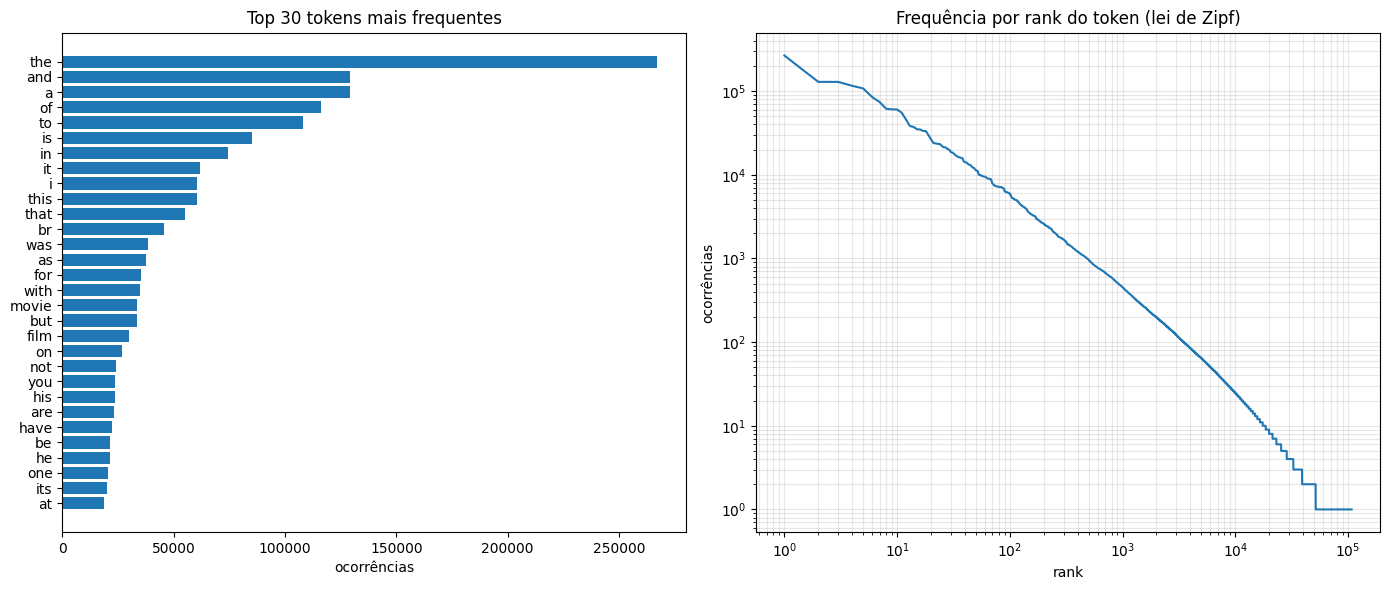

In [19]:
TOP_K = 30
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(vocab[1:TOP_K + 1][::-1], token_counts[1:TOP_K + 1][::-1])
axes[0].set_title(f'Top {TOP_K} tokens mais frequentes')
axes[0].set_xlabel('ocorrências')

axes[1].loglog(np.arange(1, len(vocab)), token_counts[1:])
axes[1].set_title('Frequência por rank do token (lei de Zipf)')
axes[1].set_xlabel('rank')
axes[1].set_ylabel('ocorrências')
axes[1].grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

Poucos tokens concentram a maior parte das ocorrências (artigos, preposições), e a cauda de palavras raras é enorme. Por isso limitamos o vocabulário aos `VOCAB_SIZE` tokens mais frequentes: a cauda acrescenta muitas dimensões com pouquíssima informação.

## 2.3 Datasets de treino, validação e teste

Os datasets finais, com batching, que serão reaproveitados por todos os modelos da aula:

In [20]:
# batch grande acelera o treino sem piorar o resultado: com BS=32 cada época levava ~2x mais tempo
BATCH_SIZE = 256

train_ds = get_dataset(train_corpus, train_labels, BATCH_SIZE, shuffle=True, drop=True)
val_ds   = get_dataset(val_corpus, val_labels, BATCH_SIZE)
test_ds  = get_dataset(test_corpus, test_labels, BATCH_SIZE)

Antes de seguir, uma função utilitária para inspecionar qualquer dataset vetorizado. Vamos chamá-la toda vez que criarmos um novo dataset:

In [21]:
def inspect_batch(dataset):
    """Mostra o shape, dtype e um exemplo de um batch, útil para checar se o pipeline está correto."""
    for inputs, targets in dataset:
        print("inputs.shape:", inputs.shape)
        print("inputs.dtype:", inputs.dtype)
        print("targets.shape:", targets.shape)
        print("targets.dtype:", targets.dtype)
        print("inputs[0]:", inputs[0])
        print("targets[0]:", targets[0])
        break


inspect_batch(train_ds)

inputs.shape: (256,)
inputs.dtype: <dtype: 'string'>
targets.shape: (256, 1)
targets.dtype: <dtype: 'uint8'>
inputs[0]: tf.Tensor(b'This short is a puzzlement. Words fail me here, as this is almost indescribable, Technically exceptional after more than 90 years (the visuals are remarkable and even occasionally amazing), this is not something you watch if you like things that are mundane or "normal\'-because it most certainly is not either. This be an odd one, gang. Well worth checking out, but if things like Ren and Stimpy make your head hurt, you may want to skip this. Recommended.', shape=(), dtype=string)
targets[0]: tf.Tensor([1], shape=(1,), dtype=uint8)


# 3. Modelos Bag-of-Words

A partir daqui, cada seção testa uma forma diferente de representar o texto, a etapa de vetorização, mantendo o mesmo modelo raso (`ngram_model`), para isolar o efeito da representação.

Três funções utilitárias vão se repetir em todas as seções a seguir:

- `vectorize_datasets`: vetoriza os três splits de uma vez;
- `plot_history`: curvas de loss e acurácia por época;
- `train_and_report`: treina, salva o melhor checkpoint, avalia no teste e registra o resultado em `benchmark.csv`. Por padrão segue `RUN_ALL`; quando não treina, apenas mostra a arquitetura do modelo.

In [22]:
VECTORIZERS = {}  # {nome do modelo: vetorizador}, usado para montar o modelo de inferência


def vectorize_datasets(vectorizer, train_ds, val_ds, test_ds):
    """
    Adapta o vetorizador só no corpus de treino, depois aplica a vetorização
    em tempo real nos três splits, dentro do próprio pipeline tf.data.
    """
    # NOTE: adapt no array (ordem fixa) garante o mesmo vocabulário a cada execução,
    #       condição para reaproveitar checkpoints salvos em outra sessão.
    #       OBS: tokens de frequência empatada poderiam parar em índices diferentes
    #            por mero acaso.
    vectorizer.adapt(train_corpus) # <= determinístico
    return [ds.map(lambda x, y: (vectorizer(x), y), num_parallel_calls=tf.data.AUTOTUNE)
            for ds in (train_ds, val_ds, test_ds)]


def plot_history(history):
    """Curvas de loss e acurácia, treino vs validação."""
    df = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ['loss', 'accuracy']):
        df[[metric, f'val_{metric}']].plot(ax=ax, title=metric, xlabel='epoch', grid=True)
    plt.show()


def train_and_report(name, model, vectorizer, datasets, lr=1e-2, epochs=100, run=None):
    """
    Treina o modelo, salva o melhor checkpoint (menor val_loss), avalia esse checkpoint
    no conjunto de teste e registra o resultado em BENCHMARK_CSV.
    """
    VECTORIZERS[name] = vectorizer
    model.summary()
    if not (RUN_ALL if run is None else run):
        print(f'Treino de "{name}" pulado: resultado disponível na seção 5 (benchmark).')
        return

    train_ds, val_ds, test_ds = datasets
    checkpoint = f'models/{name}.keras'
    model.compile(optimizer=keras.optimizers.Adam(lr), loss='binary_crossentropy', metrics=['accuracy'])
    callbacks = [
        keras.callbacks.ModelCheckpoint(checkpoint, save_best_only=True),
        keras.callbacks.EarlyStopping(patience=5),
    ]

    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks)
    train_time = time.time() - start
    plot_history(history.history)

    # avalia o melhor checkpoint, não os pesos da última época
    results = keras.models.load_model(checkpoint).evaluate(test_ds, return_dict=True)

    # registra o resultado, substituindo uma execução anterior do mesmo modelo
    log = pd.DataFrame([{
        'name': name,
        'test_accuracy': results['accuracy'],
        'test_loss': results['loss'],
        'best_epoch': int(np.argmin(history.history['val_loss'])) + 1,
        'params': model.count_params(),
        'train_time_min': train_time / 60,
        'checkpoint': checkpoint,
    }])
    if os.path.exists(BENCHMARK_CSV):
        previous = pd.read_csv(BENCHMARK_CSV)
        log = pd.concat([previous[previous['name'] != name], log])
    log.to_csv(BENCHMARK_CSV, index=False)

    return results

O modelo é o mesmo para as duas representações bag-of-words: uma camada densa pequena sobre o vetor de `VOCAB_SIZE` posições.

In [23]:
def ngram_model(vocab_size):
    inputs = keras.layers.Input(shape=(vocab_size,))
    # como o documento foi compactado em um vetor,
    # o modelo já pode processar diretamente em uma camada Densa
    x = keras.layers.Dense(16, activation='relu')(inputs)
    x = keras.layers.Dropout(0.5)(x)
    outputs = keras.layers.Dense(1, activation='sigmoid')(x)
    return keras.Model(inputs, outputs)

## 3.1 2-gram multi-hot

`ngrams=2` indexa palavras isoladas e também pares de palavras consecutivas, e `output_mode='multi_hot'` marca só a presença ou ausência de cada n-grama na sentença. É o bag-of-words clássico: a frequência e a posição se perdem, só sobra "quais n-gramas apareceram". Os pares recuperam um pouco da ordem ("not good" é diferente de "good").

In [25]:
bigram_vectorizer = keras.layers.TextVectorization(
    ngrams=2,
    max_tokens=VOCAB_SIZE,
    output_mode='multi_hot',
)
bigram_datasets = vectorize_datasets(bigram_vectorizer, train_ds, val_ds, test_ds)

In [26]:
bigram_vectorizer.get_vocabulary()[:50]

['[UNK]',
 np.str_('the'),
 np.str_('and'),
 np.str_('a'),
 np.str_('of'),
 np.str_('to'),
 np.str_('is'),
 np.str_('in'),
 np.str_('it'),
 np.str_('i'),
 np.str_('this'),
 np.str_('that'),
 np.str_('br'),
 np.str_('was'),
 np.str_('as'),
 np.str_('for'),
 np.str_('with'),
 np.str_('movie'),
 np.str_('but'),
 np.str_('of the'),
 np.str_('film'),
 np.str_('on'),
 np.str_('not'),
 np.str_('you'),
 np.str_('his'),
 np.str_('are'),
 np.str_('have'),
 np.str_('be'),
 np.str_('he'),
 np.str_('one'),
 np.str_('its'),
 np.str_('in the'),
 np.str_('at'),
 np.str_('all'),
 np.str_('by'),
 np.str_('an'),
 np.str_('they'),
 np.str_('from'),
 np.str_('who'),
 np.str_('so'),
 np.str_('like'),
 np.str_('her'),
 np.str_('just'),
 np.str_('or'),
 np.str_('about'),
 np.str_('has'),
 np.str_('if'),
 np.str_('out'),
 np.str_('some'),
 np.str_('there')]

In [27]:
inspect_batch(bigram_datasets[0])

inputs.shape: (256, 20000)
inputs.dtype: <dtype: 'int64'>
targets.shape: (256, 1)
targets.dtype: <dtype: 'uint8'>
inputs[0]: tf.Tensor([1 1 1 ... 0 0 0], shape=(20000,), dtype=int64)
targets[0]: tf.Tensor([1], shape=(1,), dtype=uint8)


> `run=True`: nosso treino ao vivo

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 20000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │       320,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 320,033 (1.22 MB)

 Trainable params: 320,033 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
78/78 ━━━━━━━━━━━━━━━━━━━━ 6s 47ms/step - accuracy: 0.8414 - loss: 0.3641 - val_accuracy: 0.8830 - val_loss: 0.2713
Epoch 2/100
78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.9161 - loss: 0.2108 - val_accuracy: 0.8864 - val_loss: 0.2781
Epoch 3/100
78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.9430 - loss: 0.1537 - val_accuracy: 0.8822 - val_loss: 0.3105
Epoch 4/100
78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.9513 - loss: 0.1319 - val_accuracy: 0.8834 - val_loss: 0.3198
Epoch 5/100
78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.9597 - loss: 0.1037 - val_accuracy: 0.8820 - val_loss: 0.3446
Epoch 6/100
78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.9635 - loss: 0.0916 - val_accuracy: 0.8828 - val_loss: 0.4030


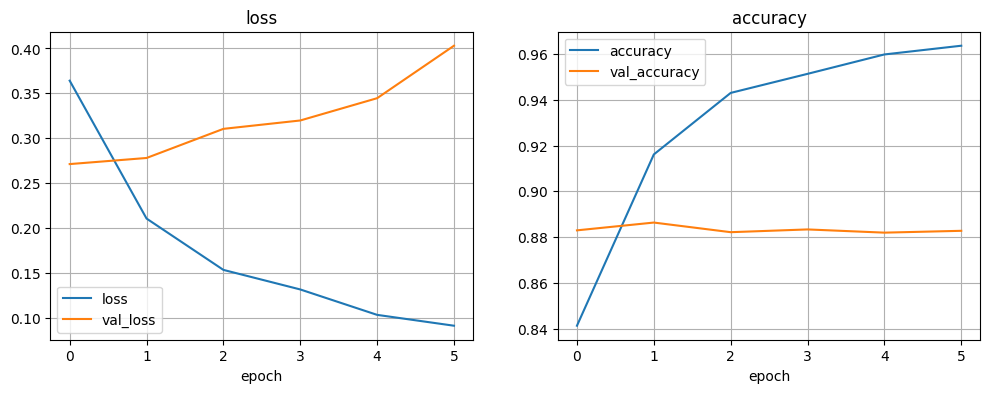

98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.8902 - loss: 0.2650


{'accuracy': 0.8902400135993958, 'loss': 0.26495036482810974}

In [28]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
model = ngram_model(VOCAB_SIZE)
train_and_report('binary_2gram', model, bigram_vectorizer, bigram_datasets, run=True)

## 3.2 TF-IDF

Term Frequency, Inverse Document Frequency: pondera cada n-grama pela frequência na sentença, dividida pela frequência no corpus inteiro. N-gramas muito comuns em todo o corpus recebem peso baixo, os mais raros e distintivos recebem peso alto.

In [30]:
tfidf_vectorizer = keras.layers.TextVectorization(
    ngrams=2,
    max_tokens=VOCAB_SIZE,
    output_mode='tf_idf',
)
tfidf_datasets = vectorize_datasets(tfidf_vectorizer, train_ds, val_ds, test_ds)

In [35]:
inspect_batch(tfidf_datasets[0])

inputs.shape: (256, 20000)
inputs.dtype: <dtype: 'float32'>
targets.shape: (256, 1)
targets.dtype: <dtype: 'uint8'>
inputs[0]: tf.Tensor(
[367.93314     4.1837873   2.1341496 ...   0.          0.
   0.       ], shape=(20000,), dtype=float32)
targets[0]: tf.Tensor([1], shape=(1,), dtype=uint8)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 20000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │       320,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 320,033 (1.22 MB)

 Trainable params: 320,033 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
78/78 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.6494 - loss: 1.0714 - val_accuracy: 0.8648 - val_loss: 0.4192
Epoch 2/100
78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - accuracy: 0.7844 - loss: 0.4169 - val_accuracy: 0.8908 - val_loss: 0.3442
Epoch 3/100
78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.8197 - loss: 0.3472 - val_accuracy: 0.8878 - val_loss: 0.2992
Epoch 4/100
78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 51ms/step - accuracy: 0.8650 - loss: 0.2772 - val_accuracy: 0.8940 - val_loss: 0.2750
Epoch 5/100
78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step - accuracy: 0.8900 - loss: 0.2263 - val_accuracy: 0.8884 - val_loss: 0.2830
Epoch 6/100
78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step - accuracy: 0.8970 - loss: 0.1992 - val_accuracy: 0.8948 - val_loss: 0.2742
Epoch 7/100
78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step - accuracy: 0.9037 - loss: 0.1801 - val_accuracy: 0.8956 - val_loss: 0.2857
Epoch 8/100
78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step - accuracy: 0.9083 - loss: 0.1684 - val_accuracy: 0.

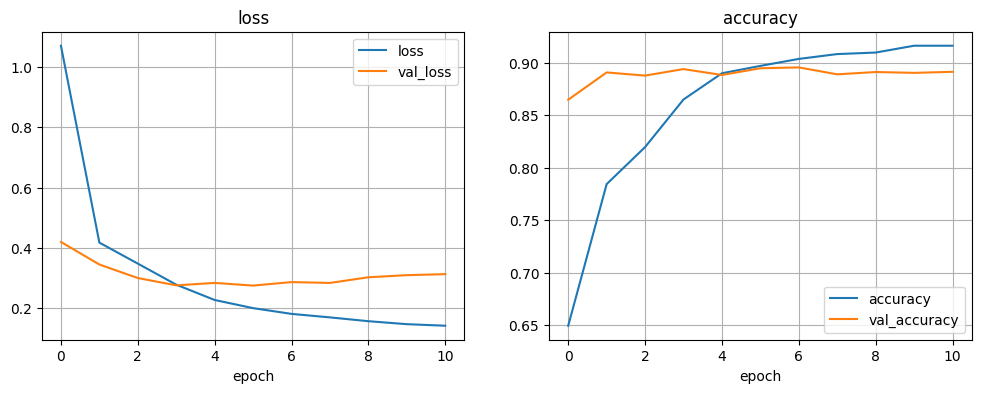

98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.8961 - loss: 0.2697


{'accuracy': 0.8960800170898438, 'loss': 0.26972711086273193}

In [31]:
# NOTE: os valores de TF-IDF não são normalizados por padrão (chegam a dezenas), e com lr=1e-2 o treino diverge
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
model = ngram_model(VOCAB_SIZE)
train_and_report('tfidf_2gram', model, tfidf_vectorizer, tfidf_datasets, lr=1e-3, run=True)

# 4. Modelos de Sequência

Os modelos anteriores tratam o texto como um saco de palavras: a ordem é descartada. Modelos de sequência recebem os tokens em ordem, e conseguem aprender padrões que dependem da posição das palavras.

Aqui, o modelo de sequência será sempre o mesmo. O que mudará entre as seções é a forma de representar cada token: **one-hot, embedding aprendido e embedding pré-treinado (GloVe)**.

## 4.1 Tamanho das sentenças

Um modelo de sequência recebe um tensor de tamanho fixo `(batch, MAX_LENGTH)`: sentenças curtas são completadas com padding, e as longas são truncadas.

<span style="color:red"> Qual é a distribuição de palavras (`tokens`) por amostra?</span> => <span style="color:green"> Vamos vetorizar todo o corpus e contar. </span>

Com `ragged=True`, a `TextVectorization` devolve cada sentença com o seu próprio tamanho, sem padding, e `row_lengths()` conta os tokens de cada uma:

In [36]:
length_vectorizer = keras.layers.TextVectorization(max_tokens=VOCAB_SIZE, ragged=True)
length_vectorizer.adapt(train_corpus)

words_per_sentence = np.concatenate(list(
    text_only_ds.map(lambda x: length_vectorizer(x).row_lengths()).as_numpy_iterator()
))

print(f'Total de sentenças: {len(words_per_sentence)}')
print(f'Número médio de palavras por amostra: {round(words_per_sentence.mean())}')
print(f'Desvio de palavras no train set: {round(words_per_sentence.std())}')
print(f'Número de palavras na maior amostra: {words_per_sentence.max()}')

Total de sentenças: 20000
Número médio de palavras por amostra: 232
Desvio de palavras no train set: 172
Número de palavras na maior amostra: 1838


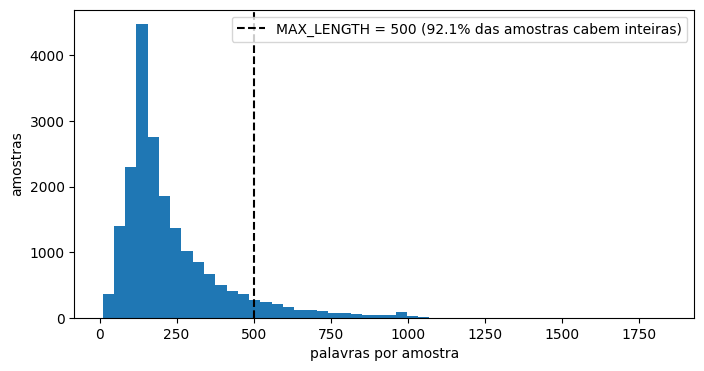

92.1% das amostras cabem inteiras em 500 tokens


In [37]:
MAX_LENGTH = 500

coverage = (words_per_sentence <= MAX_LENGTH).mean()

plt.figure(figsize=(8, 4))
plt.hist(words_per_sentence, bins=50)
plt.axvline(MAX_LENGTH, color='black', linestyle='--',
            label=f'MAX_LENGTH = {MAX_LENGTH} ({coverage:.1%} das amostras cabem inteiras)')
plt.xlabel('palavras por amostra')
plt.ylabel('amostras')
plt.legend()
plt.show()

print(f'{coverage:.1%} das amostras cabem inteiras em {MAX_LENGTH} tokens')

## 4.2 Vetorização em sequência de inteiros

Cada token vira o seu índice no vocabulário, em uma sequência de tamanho fixo (`output_sequence_length`). O índice 0 é reservado para o padding.

In [38]:
VOCAB_SIZE = 20000

int_vectorizer = keras.layers.TextVectorization(
    output_sequence_length=MAX_LENGTH,
    max_tokens=VOCAB_SIZE,
)
int_datasets = vectorize_datasets(int_vectorizer, train_ds, val_ds, test_ds)

Amostras com menos de 500 palavras são completadas com padding, o token de índice 0:

In [40]:
inspect_batch(int_datasets[0])

inputs.shape: (256, 500)
inputs.dtype: <dtype: 'int64'>
targets.shape: (256, 1)
targets.dtype: <dtype: 'uint8'>
inputs[0]: tf.Tensor(
[ 6170    14   667    34  1057  2819   134    17  4236   155   976    43
   244    96    28   453     6    27    34  9502     6  1021   241    36
     2  7723     5     2  1503     3   693     4   155  1833     6     2
   312   447    16    12    10  6084  2014    13   465    15     4  1617
     5    24   310    10   543  6084     4   250   485     2  2405  6170
   561    49    97    26    76     4  1379  2949    34  2098   250     3
   805  1283     6  4029     4   746    20  1071    17  4259     1 10457
     3 12038   137    28   184     6    26    66     4  3570    16  4914
     2 19552   381     5     4  3177   120    21    20     3     9   387
   724    15   150    28   318   683     2   396    21    24   221     3
   369     2 12321   531     3   531    11 15789    59    27  3412    45
  6170    66  1908   141     1   146    42    55     4     1   

## 4.3 One-hot

A representação mais direta: cada índice vira um vetor one-hot, do tamanho do vocabulário. O problema é que a dimensão de cada token, e portanto de todo o modelo, fica igual ao tamanho do vocabulário. Com 20 mil tokens o modelo seria inviável, então usamos um vocabulário bem menor, só com os tokens mais frequentes:

In [41]:
ONEHOT_VOCAB_SIZE = 2000

onehot_vectorizer = keras.layers.TextVectorization(
    output_sequence_length=MAX_LENGTH,
    max_tokens=ONEHOT_VOCAB_SIZE,
)
onehot_datasets = vectorize_datasets(onehot_vectorizer, train_ds, val_ds, test_ds)

Uma camada customizada faz a conversão índice → one-hot. Ela também gera a máscara de padding (`compute_mask`), para que o índice 0 seja ignorado pela `atenção` e pelo pooling, como faz o `Embedding(mask_zero=True)`:

> O mecanismo de `Atenção` é tratado seções seguintes

In [42]:
@keras.saving.register_keras_serializable(package='Custom')
class OneHot(keras.layers.Layer):
    def __init__(self, depth, **kwargs):
        super().__init__(**kwargs)
        self.depth = depth

    def call(self, inputs):
        return keras.ops.one_hot(inputs, self.depth)

    def compute_mask(self, inputs, mask=None):
        return keras.ops.not_equal(inputs, 0) #  inputs != 0

    def get_config(self):
        config = super().get_config()
        config.update({'depth': self.depth})
        return config

## 4.4 Embedding aprendido

A camada `Embedding` aprende a representar cada palavra, um índice inteiro, como um vetor denso em um espaço bem menor que o vocabulário. Em vez de um vetor esparso do tamanho de `VOCAB_SIZE`, cada palavra vira um vetor de `EMBED_DIM` posições, aprendido durante o treino. Com isso podemos voltar ao vocabulário de 20 mil tokens.

`mask_zero=True` indica que o índice 0 é padding, e deve ser ignorado ao longo da rede.

In [43]:
EMBED_DIM = 128

embedding_layer = keras.layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM, mask_zero=True)

## 4.5 Embedding pré-treinado (GloVe)

Em vez de aprender os embeddings do zero, podemos partir de vetores já treinados em um corpus gigantesco, o GloVe. A ideia é que palavras com significados parecidos já estejam próximas nesse espaço vetorial, mesmo antes de qualquer treino no IMDB.

In [29]:
if not os.path.exists('glove.6B.50d.txt'):
    !wget http://nlp.stanford.edu/data/glove.6B.zip
    !unzip -q glove.6B.zip

--2026-10-06 23:14:38--  http://nlp.stanford.edu/data/glove.6B.zip
Resolving nlp.stanford.edu (nlp.stanford.edu)... 171.64.67.140
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://nlp.stanford.edu/data/glove.6B.zip [following]
--2026-10-06 23:14:38--  https://nlp.stanford.edu/data/glove.6B.zip
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip [following]
--2026-10-06 23:14:38--  https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip
Resolving downloads.cs.stanford.edu (downloads.cs.stanford.edu)... 171.64.64.22
Connecting to downloads.cs.stanford.edu (downloads.cs.stanford.edu)|171.64.64.22|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 862182613 (822M) [application/zip]
Saving to: ‘glove.6B.zip’

glov

Carregando os vetores pré-treinados: cada linha do arquivo é uma palavra seguida dos seus coeficientes.

In [44]:
GLOVE_DIMS = 50  # dimensões disponíveis: [50, 100, 200, 300]

embeddings_index = {}  # {token: vetor de embedding}
with open(f'glove.6B.{GLOVE_DIMS}d.txt') as f:
    for line in f:
        word, coefs = line.split(maxsplit=1)
        embeddings_index[word] = np.fromstring(coefs, 'f', sep=' ')

print(f'Encontrados {len(embeddings_index)} vetores de tokens.')

Encontrados 400000 vetores de tokens.


Um teste clássico de semântica vetorial, a analogia entre países e seus líderes. Verificamos qual palavra fica mais próxima de `mussolini + (germany - italy)`:

In [45]:
keys = np.array(list(embeddings_index.keys()))
embeddings = np.array(list(embeddings_index.values()))

y = embeddings_index['mussolini'] + (embeddings_index['germany'] - embeddings_index['italy'])
distances = ((embeddings - y) ** 2).mean(axis=1) # (400k, 1)

keys[distances.argmin()]

np.str_('hitler')

Fazendo a ponte entre os dois vocabulários: construímos uma nova matriz de embeddings, do tamanho do vocabulário do IMDB, copiando o vetor do GloVe sempre que a palavra existir nos dois.

> P:"Porque?" R: É improvável que o GloVe tenha TODAS as 20000 palavras mais frequentes do IMDB. Precisamos preencher as lacunas com 0. Logo, ganhamos qualidade vetorial ao custo de perder algumas palavras do vocabulário.

In [46]:
embedding_matrix = np.zeros((VOCAB_SIZE, GLOVE_DIMS))
for i, word in enumerate(int_vectorizer.get_vocabulary()):
    if word in embeddings_index:
        embedding_matrix[i] = embeddings_index[word]

# palavras do IMDB não encontradas no GloVe permanecem como linhas de zeros
print(f'Palavras sem vetor GloVe: {(~embedding_matrix.any(axis=1)).sum()} de {VOCAB_SIZE}')

Palavras sem vetor GloVe: 1297 de 20000


Criamos a camada de embedding com essa matriz como peso inicial e `trainable=False`, para não perder o que já foi aprendido no GloVe:

In [47]:
glove_layer = keras.layers.Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=GLOVE_DIMS,
    embeddings_initializer=keras.initializers.Constant(embedding_matrix),
    trainable=False,
    mask_zero=True,
)

## 4.6 Self-attention

O coração do Transformer. Para cada token da sequência, calculamos o quanto ele deve prestar atenção em cada um dos outros tokens (produto escalar, normalizado e passado por softmax), e usamos esses pesos para montar uma nova representação do token, como uma média ponderada de toda a sequência.

Em NumPy, com operações matriciais, sem nenhum laço em Python:

In [55]:
def softmax(x):
    # keepdims=True mantém o shape, necessário para a divisão em broadcast funcionar linha a linha
    return np.exp(x) / np.exp(x).sum(axis=1, keepdims=True)


def self_attention(input_sequence):
    """input_sequence: (seq_len, embed_dim)"""
    scores = np.dot(input_sequence, input_sequence.T)  # (seq_len, seq_len): similaridade entre todos os pares
    scores /= np.sqrt(input_sequence.shape[1])        # normaliza pela raiz da dimensão
    scores = softmax(scores)                          # cada linha vira pesos que somam 1
    return np.dot(scores, input_sequence)             # média ponderada da sequência para cada token


input_sequence = np.array([
    [1, 1, 1, 1],
    [2, 2, 2, 2],
    [3, 3, 3, 3],
    [4, 4, 4, 4],
    [5, 5, 5, 5],
], dtype='float32')

self_attention(input_sequence)

array([[4.8437095, 4.8437095, 4.8437095, 4.8437095],
       [4.981343 , 4.981343 , 4.981343 , 4.981343 ],
       [4.9975147, 4.9975147, 4.9975147, 4.9975147],
       [4.9996643, 4.9996643, 4.9996643, 4.9996643],
       [4.9999547, 4.9999547, 4.9999547, 4.9999547]], dtype=float32)

No Keras, a camada `MultiHeadAttention` faz o mesmo cálculo, com projeções aprendidas de query, key e value, repetido em várias "cabeças" em paralelo. O bloco `TransformerEncoder` junta a atenção com uma feed-forward, conexões residuais e normalização:

In [56]:
@keras.saving.register_keras_serializable(package='Custom')
class TransformerEncoder(keras.layers.Layer):
    def __init__(self, embed_dim, dense_dim, num_heads, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim = embed_dim
        self.dense_dim = dense_dim
        self.num_heads = num_heads
        self.supports_masking = True

        self.attention = keras.layers.MultiHeadAttention(
            num_heads=num_heads,
            # d_k = d_model / h: as cabeças REPARTEM a dimensão (Vaswani, sec. 3.2.2)
            key_dim=embed_dim // num_heads,
            dropout=0.1,  # dropout aplicado sobre os pesos de atenção
        )
        self.dense_proj = keras.Sequential([
            keras.layers.Dense(dense_dim, activation='relu'),
            keras.layers.Dense(embed_dim),
        ])
        self.layernorm_1 = keras.layers.LayerNormalization()
        self.layernorm_2 = keras.layers.LayerNormalization()
        # dropout residual: saída de cada sub-camada antes da soma (sec. 5.4)
        self.dropout_1 = keras.layers.Dropout(0.1)
        self.dropout_2 = keras.layers.Dropout(0.1)

    def call(self, inputs, mask=None):
        if mask is not None:
            mask = mask[:, tf.newaxis, :]

        # Multi-Head Attention + Conexão Residual + LayerNorm
        attention_outputs = self.attention(query=inputs, value=inputs, key=inputs, attention_mask=mask)
        x = self.layernorm_1(inputs + self.dropout_1(attention_outputs))

        # Feed Forward + Conexão Residual + LayerNorm
        return self.layernorm_2(x + self.dropout_2(self.dense_proj(x)))

    def get_config(self):
        config = super().get_config()
        config.update({'embed_dim': self.embed_dim, 'dense_dim': self.dense_dim, 'num_heads': self.num_heads})
        return config

## 4.7 Positional Encoding

Diferente de uma RNN, a self-attention não tem noção de ordem: embaralhar os tokens de entrada dá o mesmo resultado. O positional encoding soma um padrão de senos e cossenos a cada posição, para que o modelo saiba onde cada token está na sequência.

In [58]:
@keras.saving.register_keras_serializable(package='Custom')
class SinCosPositionalEncoder(keras.layers.Layer):
    def __init__(self, sequence_length, embedding_dim, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = sequence_length
        self.embedding_dim = embedding_dim
        self.pos_encoding = self._get_positional_encoding(sequence_length, embedding_dim)
        self.supports_masking = True

    def _get_positional_encoding(self, seq_len, d_model):
        pos = np.arange(seq_len)[:, np.newaxis]  # (seq_len, 1)
        i = np.arange(d_model)[np.newaxis, :]    # (1, d_model)
        angle_rads = pos / np.power(10000, (2 * (i // 2)) / np.float32(d_model))  # (seq_len, d_model)

        angle_rads[:, 0::2] = np.sin(angle_rads[:, 0::2])  # dimensões pares: seno
        angle_rads[:, 1::2] = np.cos(angle_rads[:, 1::2])  # dimensões ímpares: cosseno
        return tf.cast(angle_rads[np.newaxis, ...], dtype=tf.float32)  # (1, seq_len, d_model)

    def call(self, inputs):
        # escala do paper (sec. 3.4): sem ela o positional encoding abafa o embedding
        inputs *= tf.math.sqrt(tf.cast(self.embedding_dim, tf.float32))
        return inputs + self.pos_encoding[:, :tf.shape(inputs)[1], :]

    def get_config(self):
        config = super().get_config()
        config.update({'sequence_length': self.sequence_length, 'embedding_dim': self.embedding_dim})
        return config

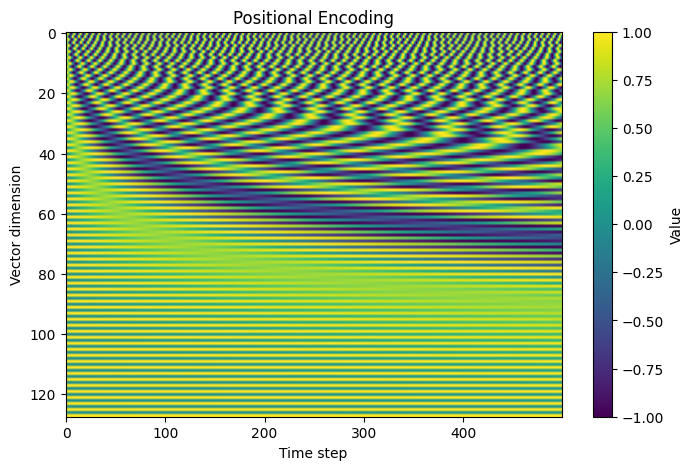

In [66]:
encoding = SinCosPositionalEncoder(MAX_LENGTH, EMBED_DIM).pos_encoding.numpy()

plt.figure(figsize=(8, 5))
plt.imshow(encoding[0].T, aspect='auto', cmap='viridis')
plt.xlabel('Time step')
plt.ylabel('Vector dimension')
plt.title('Positional Encoding')
plt.colorbar(label='Value')
plt.show()

Com o GloVe em mãos, dá para ver o efeito do positional encoding em uma sentença real, antes e depois da soma:

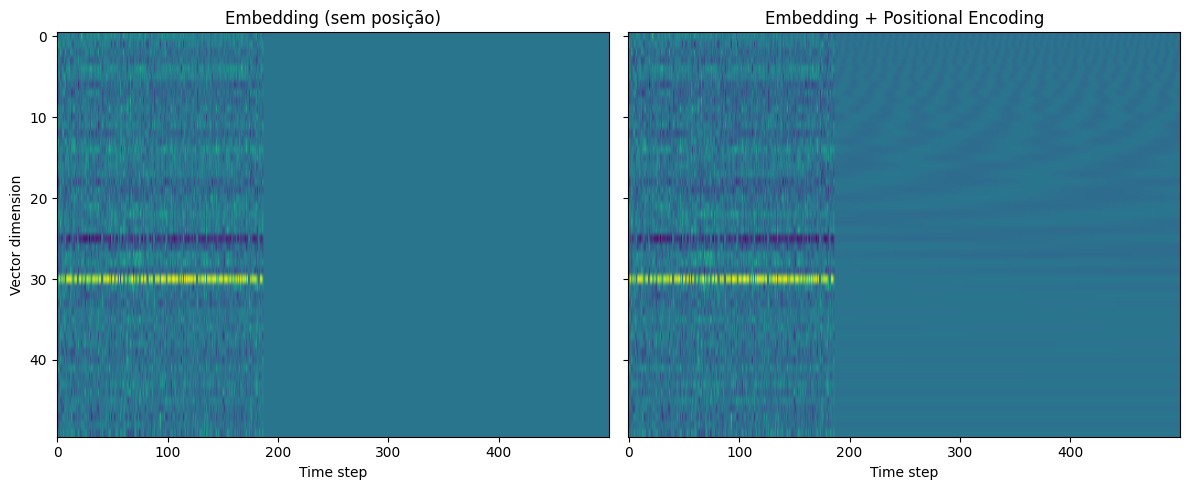

In [68]:
x, _ = next(iter(int_datasets[0]))
embedded_sentence = glove_layer(x)[0].numpy()
encoded_sentence = SinCosPositionalEncoder(MAX_LENGTH, GLOVE_DIMS)(glove_layer(x))[0].numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, sentence, title in zip(axes, [embedded_sentence, encoded_sentence],
                               ['Embedding (sem posição)', 'Embedding + Positional Encoding']):
    ax.imshow(sentence.T, aspect='auto', cmap='viridis')
    ax.set_title(title)
    ax.set_xlabel('Time step')
axes[0].set_ylabel('Vector dimension')
plt.tight_layout()
plt.show()

## 4.8 Modelagem

O Transformer desta aula recebe a camada de representação dos tokens (`token_layer`) como parâmetro: é a única peça que muda entre os modelos a seguir. Depois dela vêm o positional encoding, um bloco `TransformerEncoder` e um `GlobalAveragePooling1D` para resumir a sequência antes da camada de saída.

In [ ]:
DENSE_DIM = 256
NUM_HEADS = 4


def transformer_model(token_layer, embed_dim, max_len=MAX_LENGTH, dense_dim=DENSE_DIM, num_heads=NUM_HEADS):
    inputs = keras.layers.Input(shape=(max_len,), dtype='int64')
    x = token_layer(inputs)  # (batch, max_len) -> (batch, max_len, embed_dim)

    x = SinCosPositionalEncoder(max_len, embed_dim)(x)
    x = keras.layers.SpatialDropout1D(0.1)(x)  # descarta alguns tokens inteiros, junto com o PE

    x = TransformerEncoder(embed_dim, dense_dim, num_heads)(x)

    x = keras.layers.GlobalAveragePooling1D()(x)
    x = keras.layers.Dropout(0.25)(x)
    outputs = keras.layers.Dense(1, activation='sigmoid')(x)
    return keras.Model(inputs, outputs)

### 4.8.1 One-hot

In [ ]:
# NOTE: modelo pesado, ~16GB de GPU com BATCH_SIZE=256. Em GPUs de 16GB (ex.: T4), reduza ONEHOT_VOCAB_SIZE
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
model = transformer_model(OneHot(ONEHOT_VOCAB_SIZE), embed_dim=ONEHOT_VOCAB_SIZE)
train_and_report('transformer_onehot', model, onehot_vectorizer, onehot_datasets, lr=1e-3)

### 4.8.2 Embedding aprendido

In [ ]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
model = transformer_model(embedding_layer, embed_dim=EMBED_DIM)
train_and_report('transformer_embedding', model, int_vectorizer, int_datasets, lr=1e-3)

### 4.8.3 GloVe

In [ ]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
model = transformer_model(glove_layer, embed_dim=GLOVE_DIMS)
train_and_report('transformer_glove', model, int_vectorizer, int_datasets, lr=1e-3)

# 5. Benchmark

Resultado de teste de todos os modelos, lido de `benchmark.csv`. Cada linha corresponde ao melhor checkpoint (menor `val_loss`) de cada modelo.

> OBS: O arquivo `benchmarks.csv` será carregado durante a aula

> NOTA: Em virtude da aleatoriedade inerente aos modelos, você poderá obter resultados ligeiramente diferentes, ainda que com o mesmo split

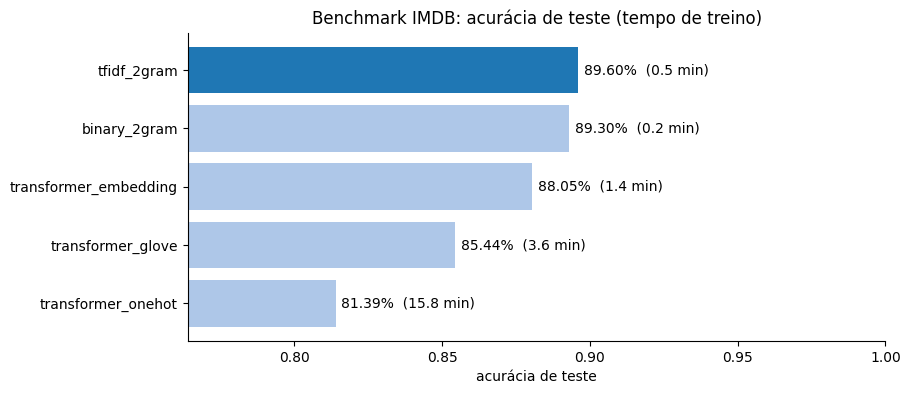

,name,test_accuracy,test_loss,best_epoch,params,train_time_min,checkpoint
0,tfidf_2gram,0.89596,0.266595,6,320033,0.481984,models/tfidf_2gram.keras
4,binary_2gram,0.89304,0.263982,2,320033,0.239988,models/binary_2gram.keras
2,transformer_embedding,0.88048,0.302624,2,2692609,1.421764,models/transformer_embedding.keras
3,transformer_glove,0.85444,0.336896,28,1035951,3.566705,models/transformer_glove.keras
1,transformer_onehot,0.81392,0.417125,10,17044257,15.791315,models/transformer_onehot.keras


In [69]:
benchmark = pd.read_csv(BENCHMARK_CSV).sort_values('test_accuracy')
best = benchmark.iloc[-1]

fig, ax = plt.subplots(figsize=(9, 0.6 * len(benchmark) + 1))
colors = ['#1f77b4' if name == best['name'] else '#aec7e8' for name in benchmark['name']]
ax.barh(benchmark['name'], benchmark['test_accuracy'], color=colors)
for i, row in enumerate(benchmark.itertuples()):
    ax.text(row.test_accuracy + 0.002, i, f'{row.test_accuracy:.2%}  ({row.train_time_min:.1f} min)', va='center')

ax.set_xlim(benchmark['test_accuracy'].min() - 0.05, 1)
ax.set_xlabel('acurácia de teste')
ax.set_title('Benchmark IMDB: acurácia de teste (tempo de treino)')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

benchmark.sort_values('test_accuracy', ascending=False)

# 6. Modelo de Inferência

## 6.1 Empacotando vetorizador e modelo

Depois de comparar as abordagens, é hora de empacotar o melhor modelo do benchmark para deploy. A ideia é que quem for usar o modelo não precise se preocupar com vetorização: a entrada é string pura, a saída é a predição.

Carregamos o checkpoint do melhor modelo e compomos duas camadas: o vetorizador correspondente seguido do modelo. Como o vetorizador aceita qualquer string, o shape de entrada é livre, `(1,)`:

In [ ]:
print(f"Melhor modelo: {best['name']} | acurácia de teste: {best['test_accuracy']:.2%}")

model = keras.models.load_model(best['checkpoint'])

# VECTORIZERS só preenchido durante os treinamentos
# se você não tiver, substitua manualmente pelo vectorizer desejado
vectorizer = tfidf_vectorizer # VECTORIZERS[best['name']] # tfidf_vectorizer foi o meu melhor

inputs = keras.layers.Input(shape=(1,), dtype='string')
outputs = model(vectorizer(inputs))

inf_model = keras.Model(inputs, outputs)
inf_model.save(f"inference_{best['name']}.keras")
inf_model.summary()

## 6.2 Inferência em produção

Testando com frases novas, escritas à mão. O modelo recebe texto puro, sem nenhum pré-processamento manual:

In [ ]:
queries = tf.convert_to_tensor([
    'This movie was absolutely breathtaking, I cried at the end and would happily watch it again tomorrow!',
    'Terrible acting, a nonsense script and two hours of my life that I will never get back.',
    'The worst film I have ever seen, painfully boring from the first minute to the very last.',
    'loved it',
    'It manages to be entertaining.',
    'It barely manages to be entertaining.',
])
inf_model.predict(queries)